In [ ]:
from utils import trainingHR, resultsAnalysis, CPAnalysis, plot_CPs, get_distrib_HR
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import warnings
import numpy as np
from scipy.stats import uniform, loguniform, randint
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt


##### Point prediction

###### Training

In [ ]:
train = trainingHR('global_data_7_july_2023_16_may_2025.xlsx')
n_iter_search=200
train.predictions_HR('FC_moyenne',5,n_iter_search, True)

###### Results analysis

In [ ]:
results=resultsAnalysis('results/07072023_16052025_full_prediction.csv')
dict_best_mod_player=results.count_best_model()
results.mean_std()
results.plot_bins('MAE',5)


##### Conformal Prediction

###### Computation

In [ ]:
conformal_prediction=trainingHR('global_data_7_july_2023_16_may_2025.xlsx')
threshold_nb_data=600
test_size=0.1 
calibration_size=0.2  
target='FC_moyenne'
alpha=[0.1]
alphas=np.concatenate((alpha,np.linspace(0.05,0.3,20)))
path_result='results/07072023_16052025_full_prediction.csv'
dict_params_search_qr_l={"xgb":{"scaling":[MinMaxScaler(),StandardScaler()],"model__n_estimators": randint(200,1000), 
                    "model__max_depth":randint(4,12), "model__learning_rate": loguniform(1e-3, 1e-1)},
                    "lgbm":{"scaling":[MinMaxScaler(),StandardScaler()],"model__n_estimators": randint(200,1000), 
                    "model__max_depth":randint(4,12), "model__learning_rate": loguniform(1e-3, 1e-1)}
                    }
dict_params_search_qr_u={"xgb":{"n_estimators": randint(200,1000), "max_depth":randint(4,12), "learning_rate": loguniform(1e-3, 1e-1)},
                         "lgbm":{"n_estimators": randint(200,1000), "max_depth":randint(4,12), "learning_rate": loguniform(1e-3, 1e-1)}
                         }  
dict_params_search={                        
                "rf": {"scaling":[MinMaxScaler(),StandardScaler()],'model__n_estimators': randint(200,1000),'model__max_depth' : randint(4,12)},
                "svr": {"scaling":[MinMaxScaler(),StandardScaler()],'model__kernel':['rbf','linear','sigmoid'], "model__gamma": loguniform(1e-4,10), "model__C": loguniform(5e-2,5e4)},
                "xgb": {"scaling":[MinMaxScaler(),StandardScaler()],"model__n_estimators": randint(200,1000), "model__max_depth":randint(4,12), "model__learning_rate": loguniform(1e-3, 1e-1)},                
                "kr": {"scaling":[MinMaxScaler(),StandardScaler()],'model__kernel':['rbf','linear','sigmoid'], "model__alpha": loguniform(1e-5,10), "model__gamma": loguniform(1e-4,10)},
                "lgbm": {"scaling":[MinMaxScaler(),StandardScaler()],"model__n_estimators": randint(200,1000), "model__max_depth":randint(4,12), "model__learning_rate": loguniform(1e-3, 1e-1)}          
                }                 
cv_search=5
cv_CV_plus=20
n_iter_search=200

conformal_prediction.split_conformal_prediction(threshold_nb_data=threshold_nb_data,test_size=test_size,calibration_size=calibration_size,target=target,dict_params_search=dict_params_search,cv_search=cv_search,n_iter_search=n_iter_search,alphas=alphas,save_results=True,best_regressor=True,path_result=path_result,is_balanced=True)
conformal_prediction.conformalized_quantile_regression(threshold_nb_data=threshold_nb_data, test_size=test_size, calibration_size=calibration_size, target=target, dict_params_search_qr_l=dict_params_search_qr_l, dict_params_search_qr_u=dict_params_search_qr_u, cv_search=cv_search, n_iter_search=n_iter_search, alphas=alpha, save_results=True,best_regressor=True,path_result=path_result,is_balanced=True)
conformal_prediction.cross_conformal_prediction(threshold_nb_data=threshold_nb_data,test_size=test_size,target=target, alphas=alphas, dict_params_search=dict_params_search,cv_search=cv_search,n_iter_search=n_iter_search,save_results=True,best_regressor=True,path_result=path_result,cv_CV_plus=cv_CV_plus,is_balanced=True)
conformal_prediction.cross_conformal_prediction(threshold_nb_data=threshold_nb_data,test_size=test_size,target=target, alphas=alphas, dict_params_search=dict_params_search,cv_search=cv_search,n_iter_search=n_iter_search,save_results=True,best_regressor=True,path_result=path_result,is_jackknife_plus=True,is_balanced=True)


###### Plot results

Coverage, TPR, PPV and NPV
(np.float64(0.9118127381600436), np.float64(0.5035383777898748), np.float64(0.8509659613615456), np.float64(0.6474681097796676))
(np.float64(0.9134458356015243), np.float64(0.3004899292324442), np.float64(0.7763713080168776), np.float64(0.5663179210259872))
(np.float64(0.9221556886227544), np.float64(0.5264017419706043), np.float64(0.8711711711711712), np.float64(0.6606864274570983))
(np.float64(0.909635274904736), np.float64(0.5508982035928144), np.float64(0.8590831918505942), np.float64(0.6694711538461539))

Interval size
mean      19.648129
std        2.887959
median    19.653289
dtype: float64
mean      23.792773
std        5.118189
median    23.534026
dtype: float64
mean      18.708987
std        2.492950
median    18.929941
dtype: float64
mean      18.524891
std        2.437327
median    18.451592
dtype: float64


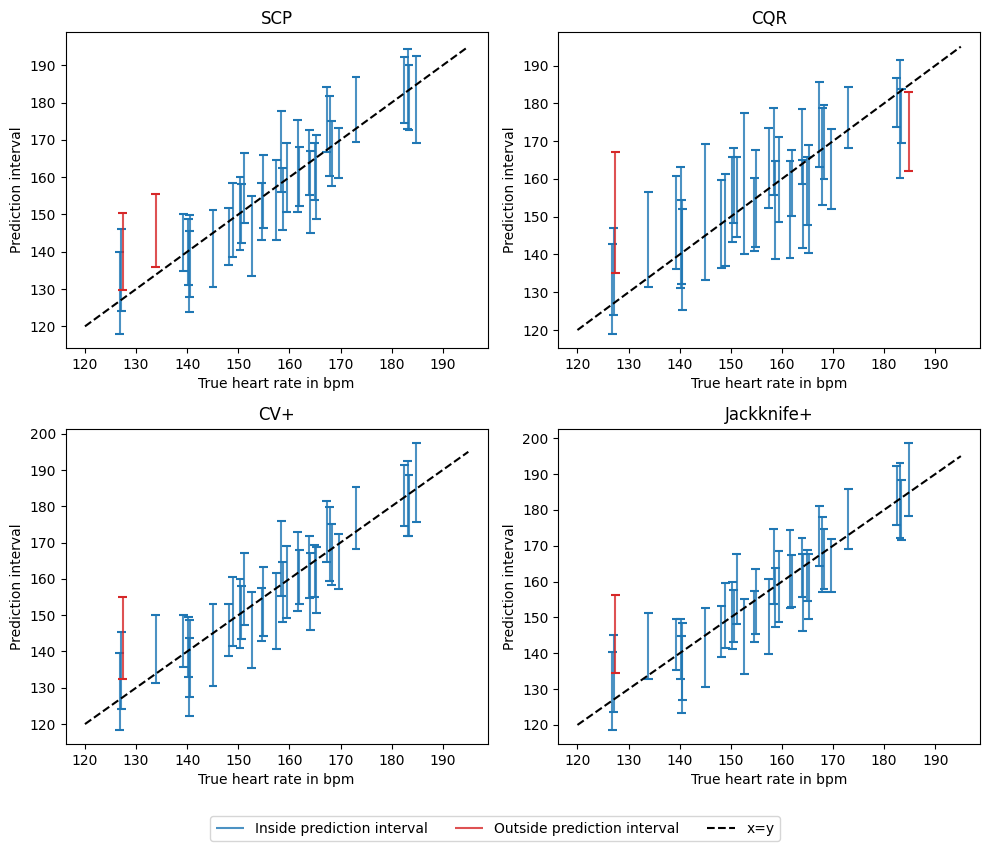

In [ ]:
results_scp=CPAnalysis('results/SCP/balanced_nb_anomalies/07072023_16052025_alpha0.1.csv')
results_cqr=CPAnalysis('results/CQR/balanced_nb_anomalies/07072023_16052025_alpha0.1.csv')
results_cv_plus=CPAnalysis('results/CV+/balanced_nb_anomalies/07072023_16052025_cvccp20alpha0.1.csv')
results_cv_plus_100=CPAnalysis('results/CV+/100_anomalies/07072023_16052025_cvccp100alpha0.1.csv')
results_jackknife_plus=CPAnalysis('results/Jackknife+/balanced_nb_anomalies/07072023_16052025_alpha0.1.csv')
print('Coverage, TPR, PPV and NPV')
print(results_scp.coverage_and_anomalies())
print(results_cqr.coverage_and_anomalies())
print(results_cv_plus.coverage_and_anomalies())
print(results_jackknife_plus.coverage_and_anomalies())
print('')
print('Interval size')
print(results_scp.interval_size_analysis())
print(results_cqr.interval_size_analysis())
print(results_cv_plus.interval_size_analysis())
print(results_jackknife_plus.interval_size_analysis())

datasets = [
        results_scp.results[results_scp.results['Anomaly ?']==0],
        results_cqr.results[results_cqr.results['Anomaly ?']==0],
        results_cv_plus.results[results_cv_plus.results['Anomaly ?']==0],
        results_jackknife_plus.results[results_jackknife_plus.results['Anomaly ?']==0]
    ]
name=["SCP","CQR","CV+","Jackknife+"]
plot_CPs(datasets,name)

###### Plot evolution interval size with alpha

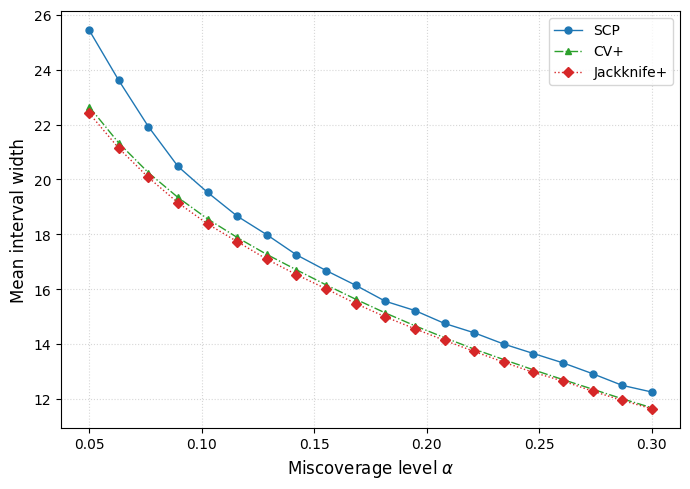

In [10]:
alpha_scp = np.linspace(0.05, 0.3, 20)
name_method=["SCP","CV+","Jackknife+"]
alpha_min, alpha_max = alpha_scp.min(), alpha_scp.max()
alpha_theory = np.linspace(alpha_min-0.01, alpha_max+0.01, 200)
styles = {
    "SCP":        dict(color="tab:blue",   marker="o", linestyle="-"),
    "CQR":        dict(color="tab:orange", marker="s", linestyle="--"),
    "CV+":        dict(color="tab:green",  marker="^", linestyle="-."),
    "Jackknife+": dict(color="tab:red",    marker="D", linestyle=":")
}
plt.figure(figsize=(7, 5))
for method in name_method:
    interval_size=[]
    for alpha in alpha_scp:
        if method=="CV+":
            result = CPAnalysis(f'results/{method}/balanced_nb_anomalies/07072023_16052025_cvccp20alpha{alpha}.csv')
        else:
            result = CPAnalysis(f'results/{method}/balanced_nb_anomalies/07072023_16052025_alpha{alpha}.csv')
        interval_stat = result.interval_size_analysis()
        interval_size.append(interval_stat['mean'])
    plt.plot(alpha_scp, interval_size,linewidth=1,markersize=5,label=method,**styles[method])
plt.xlabel(r"Miscoverage level $\alpha$", fontsize=12)
plt.ylabel("Mean interval width", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

###### Plot evolution anomalies with alpha

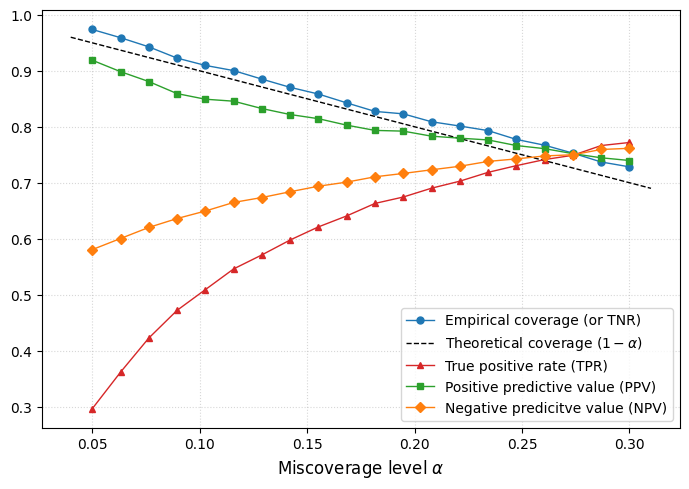

In [ ]:
coverages = []
TPR = []
PPV=[]
NPV=[]
alpha_scp = np.linspace(0.05, 0.3, 20)
for alpha in alpha_scp:
    result = CPAnalysis(f'results/SCP/balanced_nb_anomalies/07072023_16052025_alpha{alpha}.csv')
    coverage, anomalies_detected,ppv,npv = result.coverage_and_anomalies()
    coverages.append(coverage)
    TPR.append(anomalies_detected)
    PPV.append(ppv)
    NPV.append(npv)

alpha_min, alpha_max = alpha_scp.min(), alpha_scp.max()
alpha_theory = np.linspace(alpha_min-0.01, alpha_max+0.01, 200)
plt.figure(figsize=(7, 5))
plt.plot(alpha_scp, coverages,color="tab:blue",marker="o",linestyle="-",linewidth=1,markersize=5,label="Empirical coverage (or TNR)")
plt.plot(alpha_theory, 1-alpha_theory,color="black",linestyle="--",linewidth=1,label=r"Theoretical coverage $(1-\alpha$)")
plt.plot(alpha_scp, PPV,color="tab:green",marker="s",linestyle="-",linewidth=1,markersize=5,label="Positive predictive value (PPV)")
plt.plot(alpha_scp, NPV,color="tab:orange",marker="D",linestyle="-",linewidth=1,markersize=5,label="Negative predicitve value (NPV)")
plt.plot(alpha_scp, TPR,color="tab:red",marker="^",linestyle="-",linewidth=1,markersize=5,label="True positive rate (TPR)")
plt.xlabel(r"Miscoverage level $\alpha$", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

